In [1]:
from base.environment import Environment
import matplotlib.pyplot as plt
import pandas as pd
import random
import numpy as np

# Simulation Random Network Results

In [2]:
p_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
N_values = [10, 50]
Lambda_values = [0.1,0.2,0.3,0.4,0.5]
threshold_values = [None, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

In [3]:
df = pd.read_fwf('outputs/SIMULATIONS/df_resultsRANDOM.txt')
df.head()

,N,lambda,p,threshold,simulation,bank_failure,run_percentage
0,10,0.1,0.1,NaN,0,False,0.1
1,10,0.1,0.1,NaN,1,False,0.2
2,10,0.1,0.1,NaN,2,False,0.1
3,10,0.1,0.1,NaN,3,False,0.1
4,10,0.1,0.1,NaN,4,False,0.2


In [4]:
df_N10 = df[df['N'] == 10].copy()

pivot_tables = {}
pivot1_tables = {}

for threshold in threshold_values:

    # Select the data for this threshold
    if threshold is None:
        temp = df_N10[df_N10['threshold'].isna()]
    else:
        temp = df_N10[df_N10['threshold'] == threshold]

    # LEFT: bank failure by lambda
    pivot = temp.pivot_table(index='p', columns='lambda', values='bank_failure', aggfunc='mean')

    pivot = pivot.reindex(columns=Lambda_values)

    pivot_tables[threshold] = pivot

    # RIGHT: run percentage by bank failure
    pivot1 = pd.pivot_table(temp, index='p', columns=['bank_failure', 'lambda'], values='run_percentage', aggfunc='mean')

    pivot1_tables[threshold] = pivot1

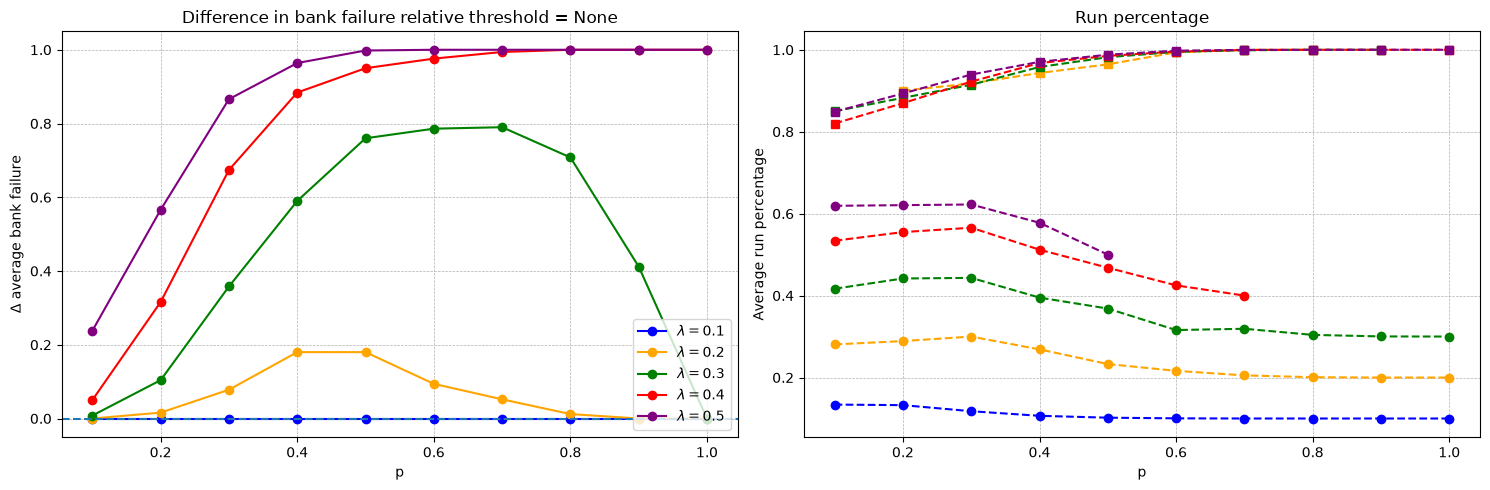

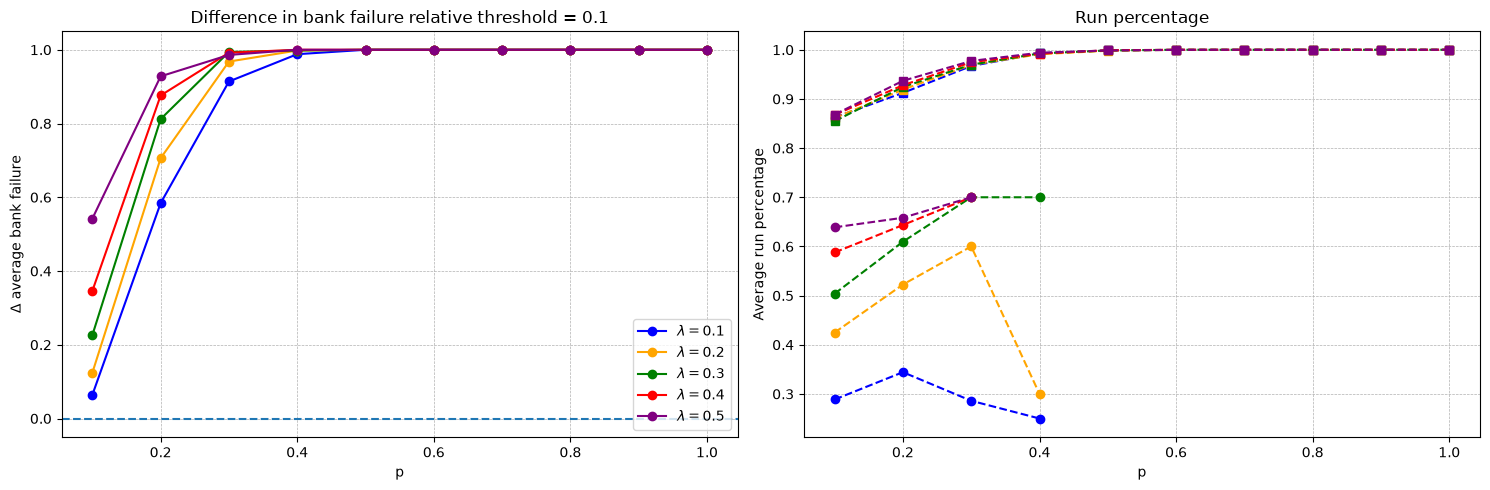

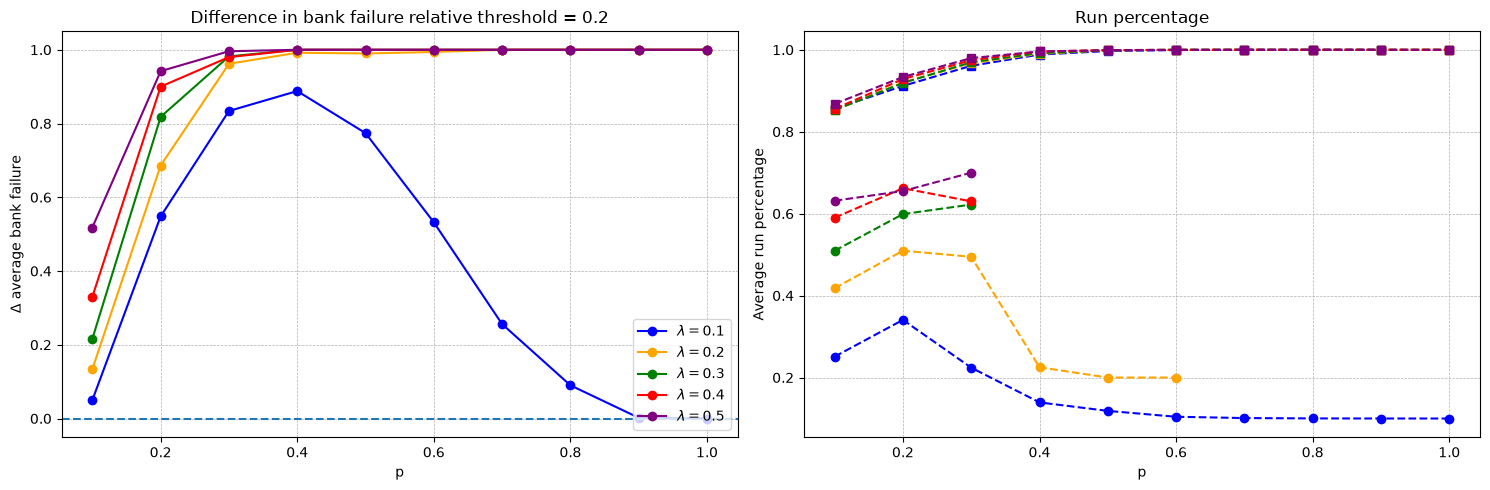

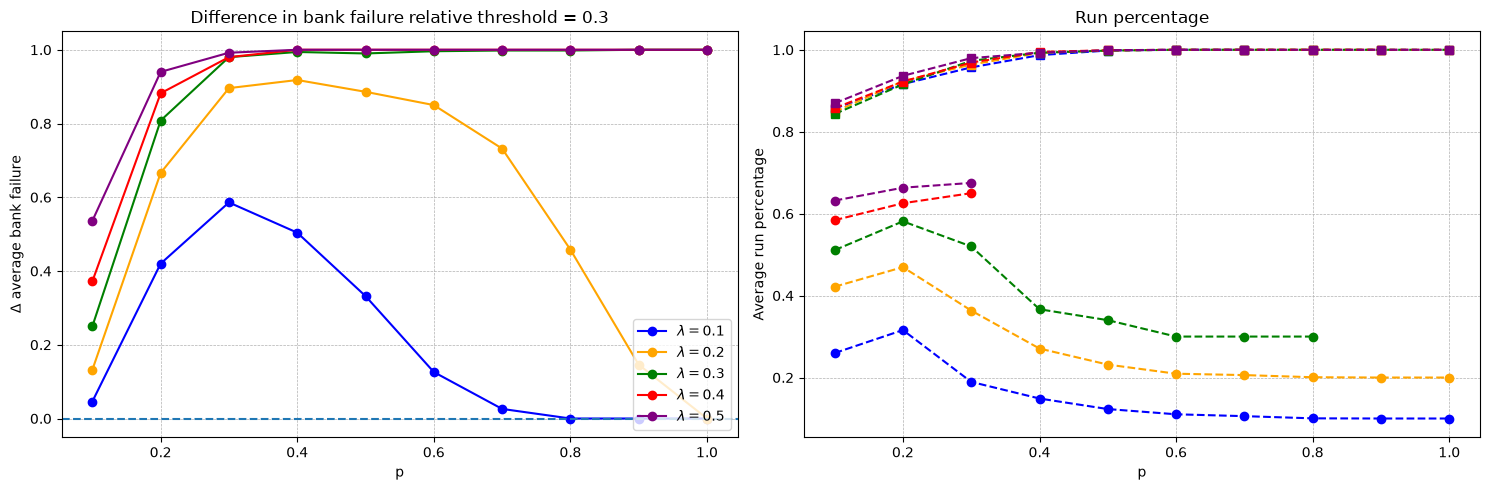

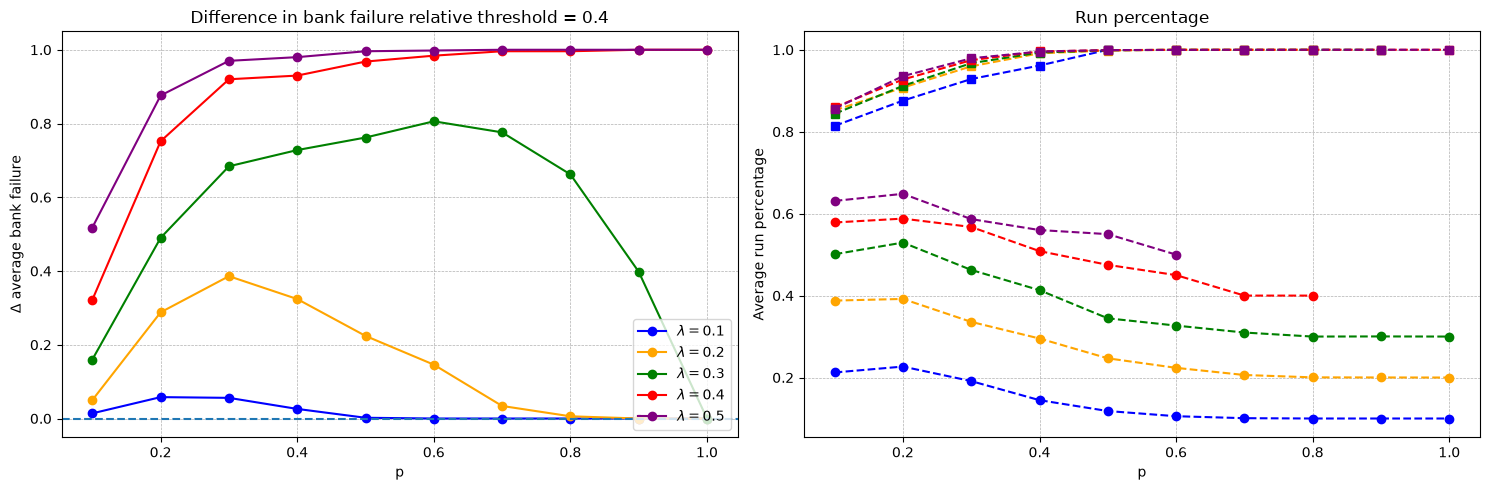

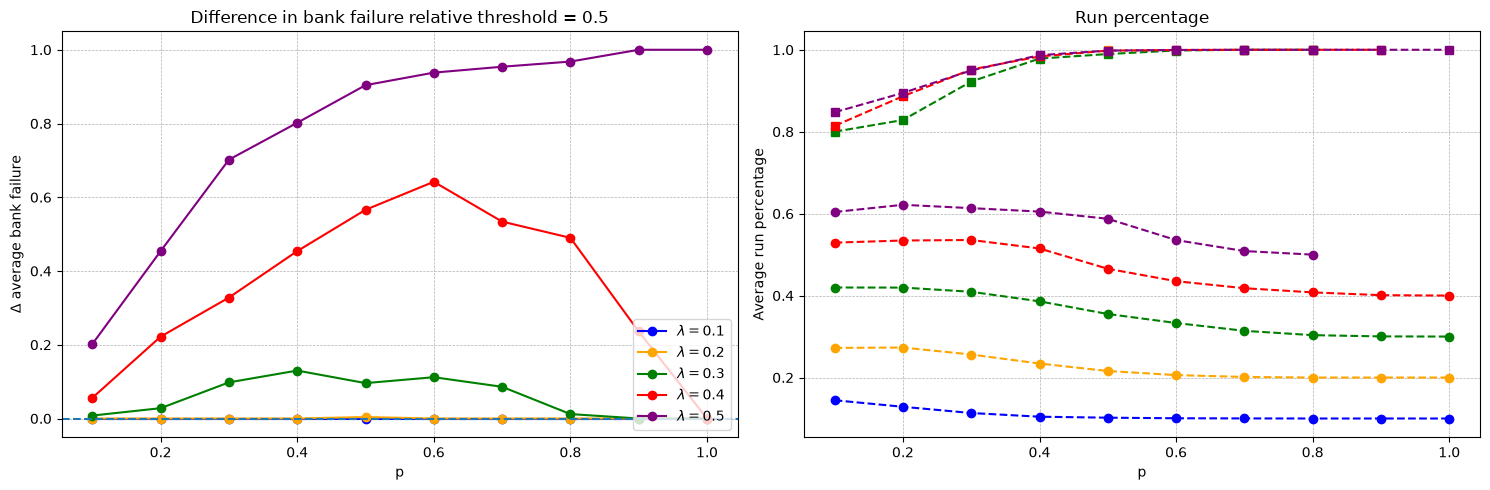

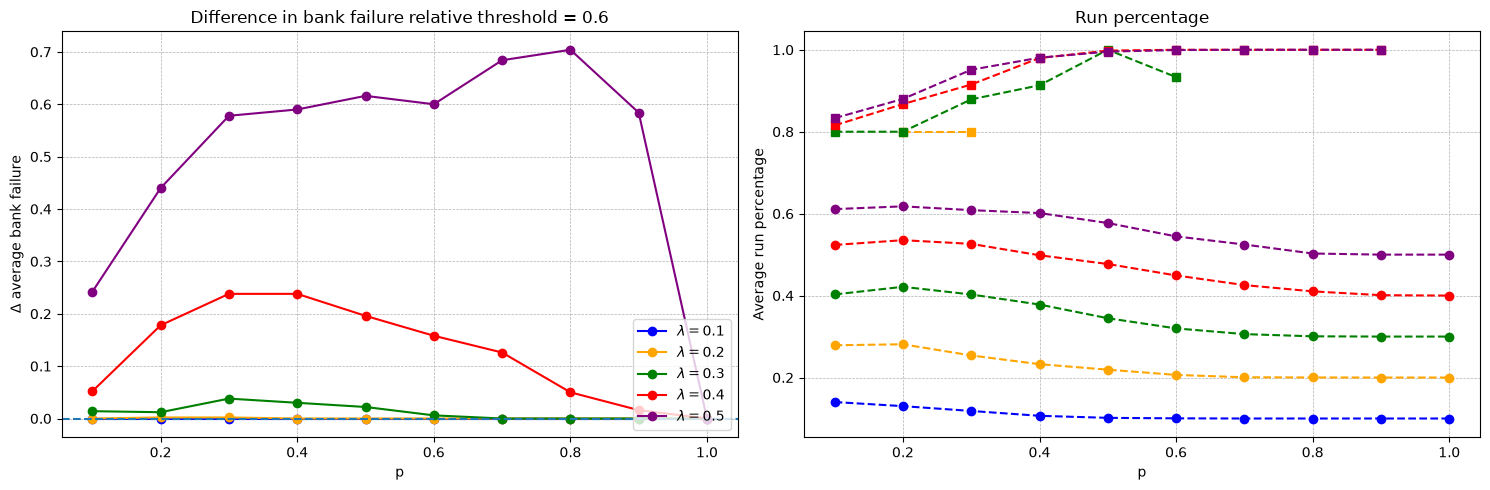

In [5]:
for threshold in threshold_values:

    pivot = pivot_tables[threshold]
    pivot1 = pivot1_tables[threshold]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # =========================
    # LEFT GRAPH
    # =========================
    ax = axes[0]

    colors = ['blue', 'orange', 'green', 'red', 'purple']

    for color, lambda_value in zip(colors, Lambda_values):
        ax.plot(pivot.index, pivot[lambda_value], marker='o', label=fr'$\lambda={lambda_value}$', color=color)

    ax.set_title(rf'Difference in bank failure relative threshold = {threshold}')
    ax.set_xlabel('p')
    ax.set_ylabel(r'$\Delta$ average bank failure')
    ax.axhline(0, linestyle='--')
    ax.legend(loc='lower right')
    ax.grid(ls='dashed', lw=0.5)


    # =========================
    # RIGHT GRAPH
    # =========================
    ax = axes[1]
    for color, lambda_value in zip(colors, Lambda_values):
        for bank_failure, lam in pivot1.columns:
            if lam == lambda_value:
                if bank_failure is False:
                    ax.plot(pivot1.index, pivot1[(bank_failure, lam)], marker='o', ls = 'dashed', color = color)
                else:
                    ax.plot(pivot1.index, pivot1[(bank_failure, lam)], marker='s', ls = 'dashed', color = color)

    ax.set_title('Run percentage')
    ax.set_xlabel('p')
    ax.set_ylabel('Average run percentage')
    ax.grid(ls='dashed', lw=0.5)

    plt.tight_layout()
    plt.show()

In [6]:
df_N50 = df[df['N'] == 50].copy()

pivot_tables = {}
pivot1_tables = {}

for threshold in threshold_values:

    # Select the data for this threshold
    if threshold is None:
        temp = df_N50[df_N50['threshold'].isna()]
    else:
        temp = df_N50[df_N50['threshold'] == threshold]

    # LEFT: bank failure by lambda
    pivot = temp.pivot_table(index='p', columns='lambda', values='bank_failure', aggfunc='mean')

    pivot = pivot.reindex(columns=Lambda_values)

    pivot_tables[threshold] = pivot

    # RIGHT: run percentage by bank failure
    pivot1 = pd.pivot_table(temp, index='p', columns=['bank_failure', 'lambda'], values='run_percentage', aggfunc='mean')

    pivot1_tables[threshold] = pivot1

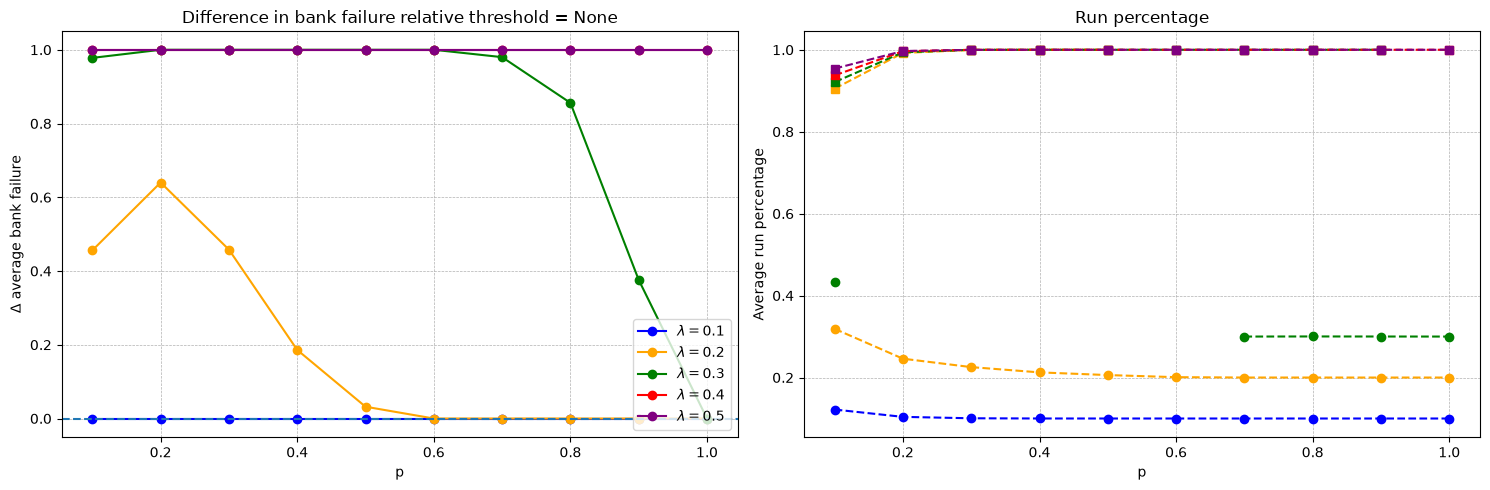

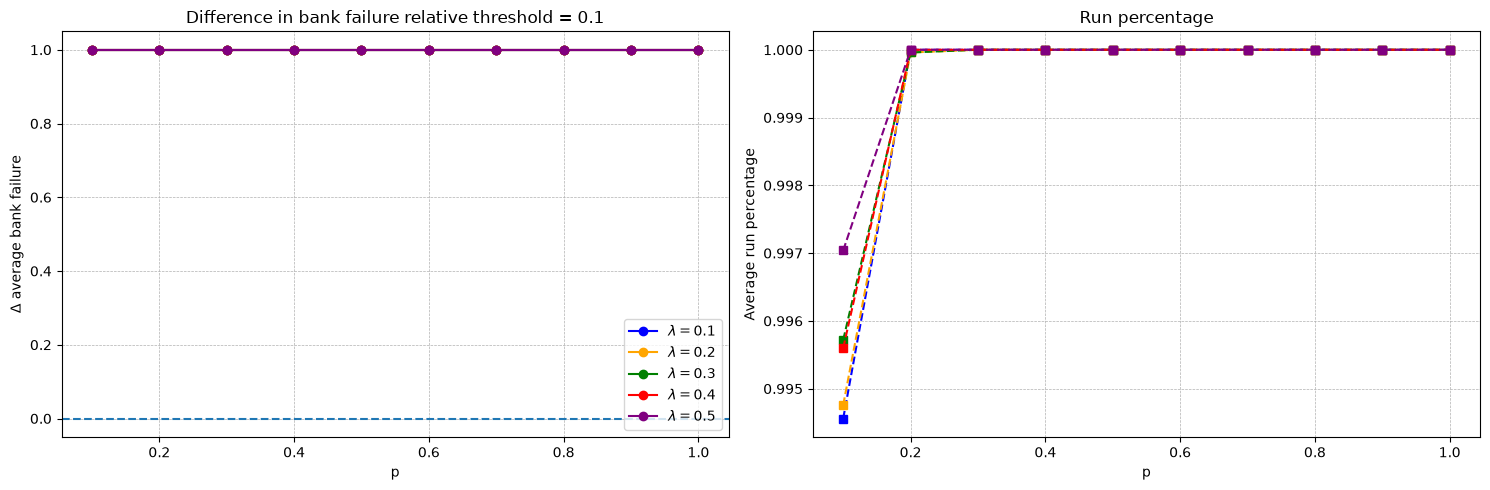

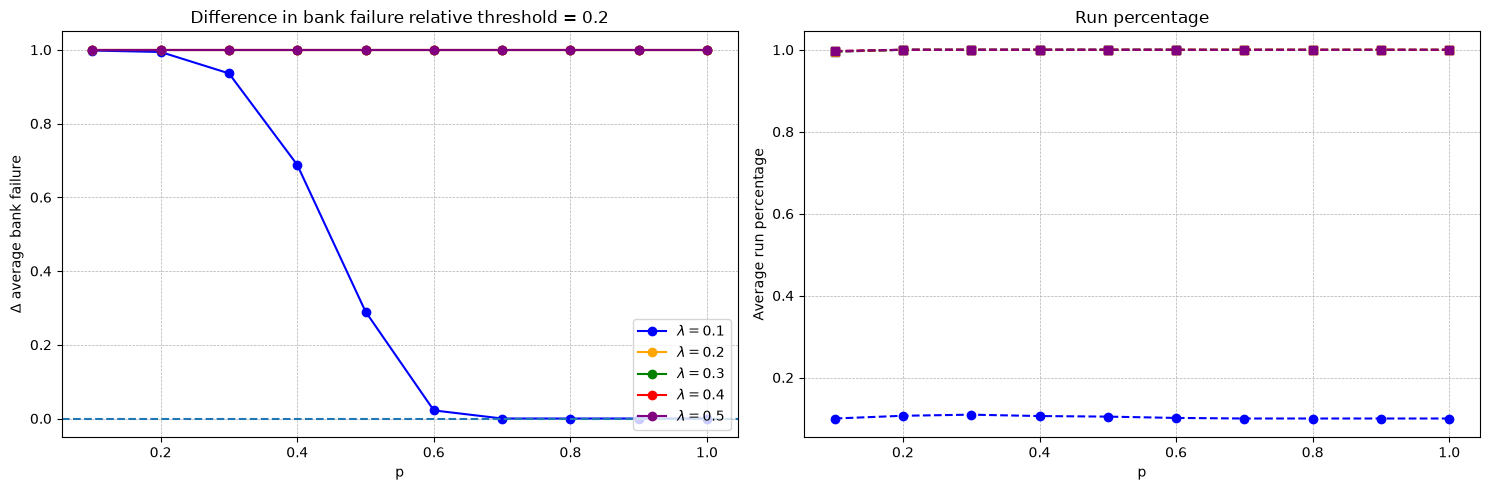

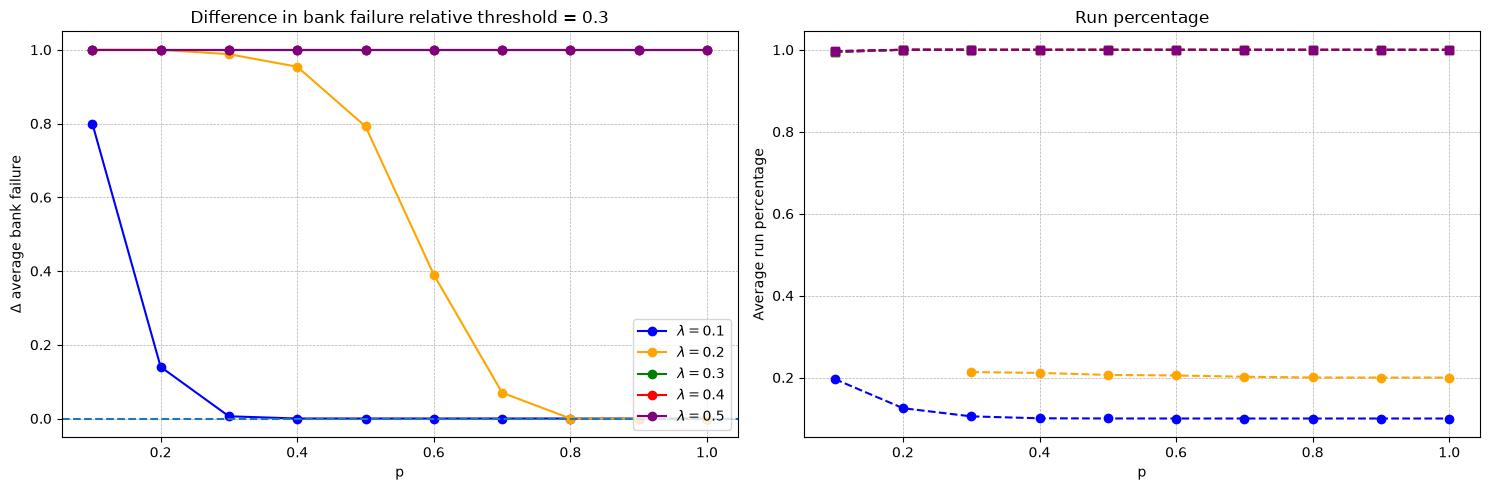

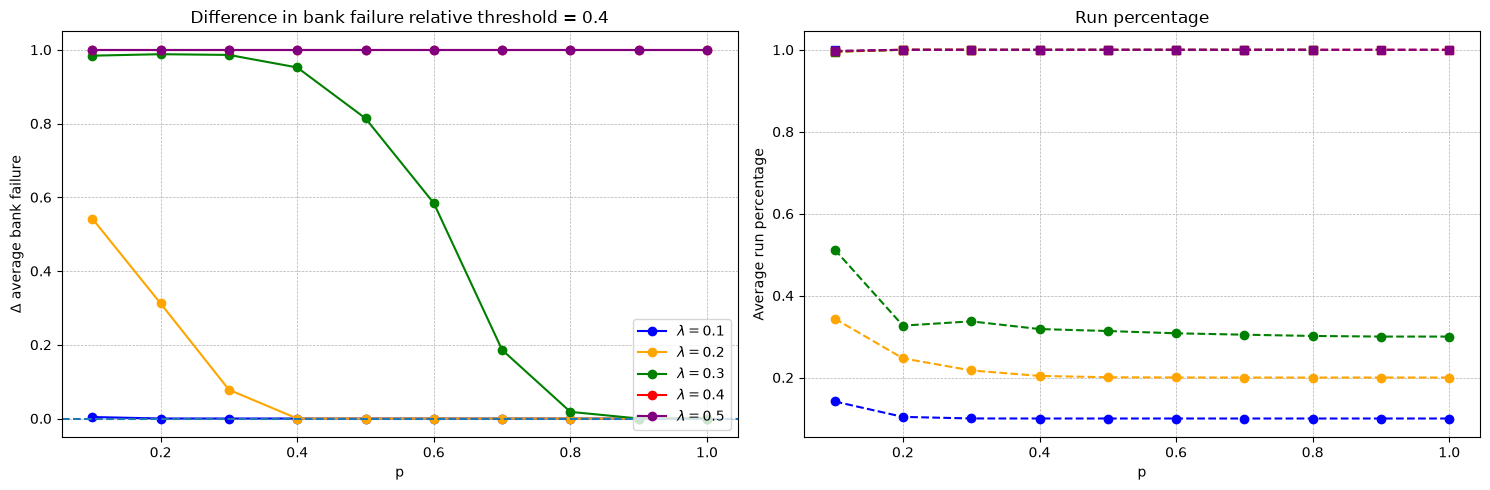

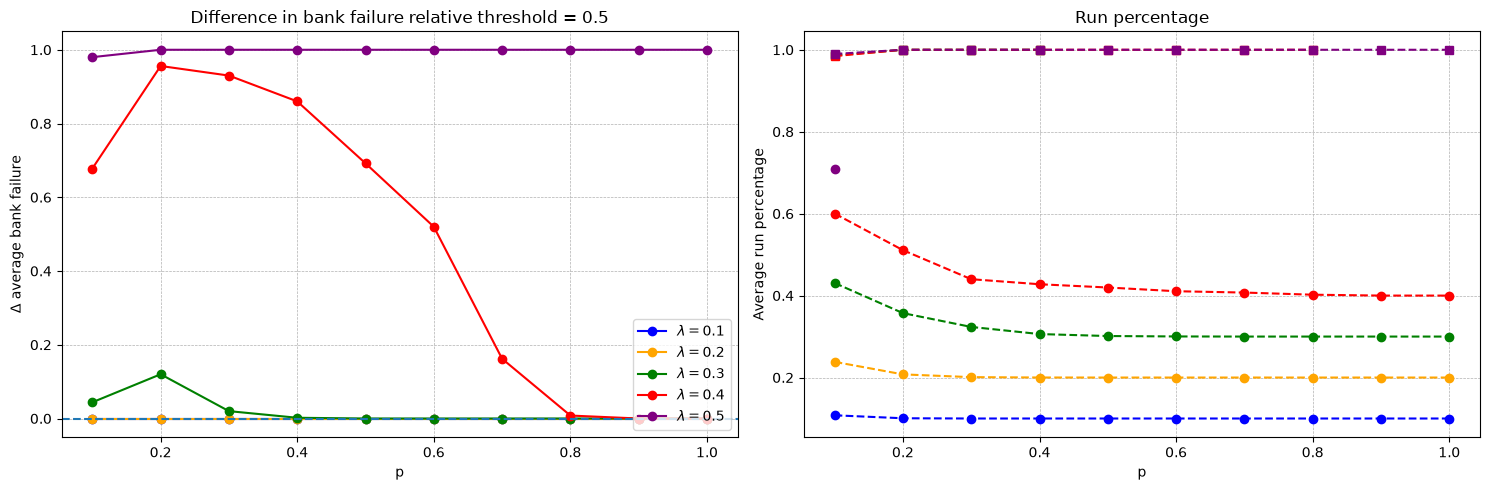

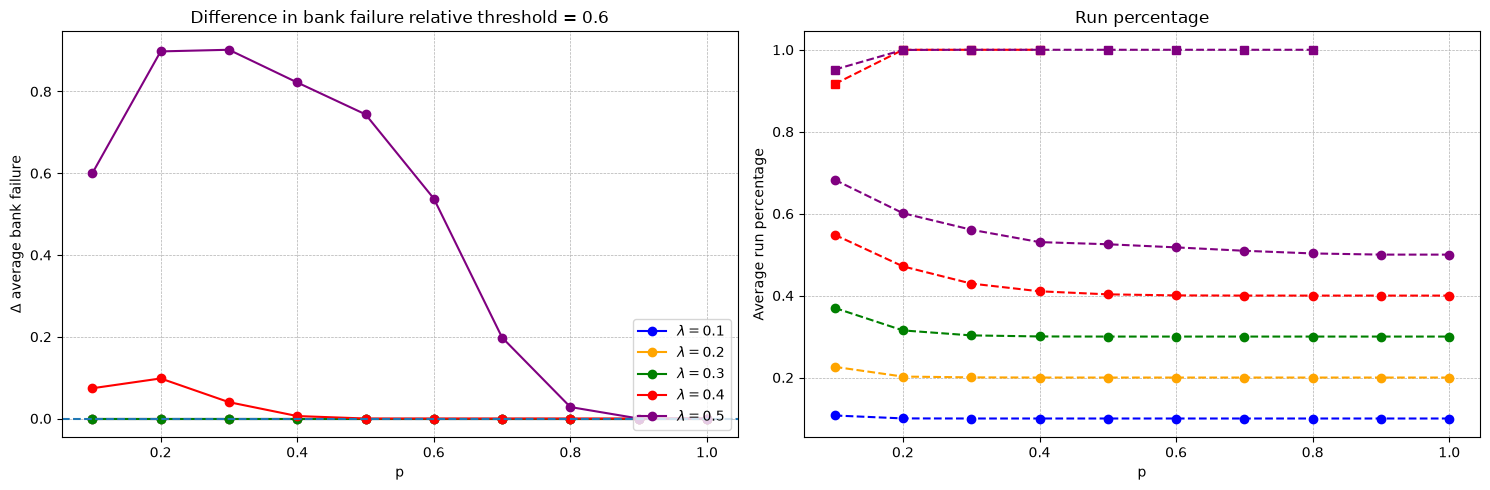

In [7]:
for threshold in threshold_values:

    pivot = pivot_tables[threshold]
    pivot1 = pivot1_tables[threshold]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # =========================
    # LEFT GRAPH
    # =========================
    ax = axes[0]

    colors = ['blue', 'orange', 'green', 'red', 'purple']

    for color, lambda_value in zip(colors, Lambda_values):
        ax.plot(pivot.index, pivot[lambda_value], marker='o', label=fr'$\lambda={lambda_value}$', color=color)

    ax.set_title(rf'Difference in bank failure relative threshold = {threshold}')
    ax.set_xlabel('p')
    ax.set_ylabel(r'$\Delta$ average bank failure')
    ax.axhline(0, linestyle='--')
    ax.legend(loc='lower right')
    ax.grid(ls='dashed', lw=0.5)


    # =========================
    # RIGHT GRAPH
    # =========================
    ax = axes[1]
    for color, lambda_value in zip(colors, Lambda_values):
        for bank_failure, lam in pivot1.columns:
            if lam == lambda_value:
                if bank_failure is False:
                    ax.plot(pivot1.index, pivot1[(bank_failure, lam)], marker='o', ls = 'dashed', color = color)
                else:
                    ax.plot(pivot1.index, pivot1[(bank_failure, lam)], marker='s', ls = 'dashed', color = color)

    ax.set_title('Run percentage')
    ax.set_xlabel('p')
    ax.set_ylabel('Average run percentage')
    ax.grid(ls='dashed', lw=0.5)

    plt.tight_layout()
    plt.show()

# Simulation Clustered Network Results

N = 50

## Number of clusters: 2

In [ ]:
p_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
N_values = [50]
cluster_values = [2,3,4]
Lambda_values = [0.1,0.2,0.3,0.4,0.5]
threshold_values = [None, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

results = []

random.seed(1)
np.random.seed(1)

for N in N_values:
    for Lambda in Lambda_values:
        for p in p_values:
            for cluster in cluster_values:
                for threshold in threshold_values:
                    print(N, Lambda, p, cluster, threshold)
                    for simulation_id in range(500):
                        if p == 0.1:
                            SIMU = Environment(N=N, Lambda=Lambda, network_type='random', threshold = threshold, p=p, liquidity_ratio=0, liquidation_discount=1, return_multiplier=0.5, theta=1, R=1.5, r=1.28)
                        else:
                            SIMU = Environment(N=N, Lambda=Lambda, network_type='clustered', threshold = threshold, number_of_clusters = cluster, p_inside=p, liquidity_ratio=0, liquidation_discount=1, return_multiplier=0.5, theta=1, R=1.5, r=1.28)
                        SIMU.simulation(printing=False)
                
                        results.append({
                            'N': N,
                            'lambda': Lambda,
                            'p': p,
                            'cluster': cluster,
                            'threshold':threshold,
                            'simulation': simulation_id,
                            'bank_failure': SIMU.bank_failure,
                            'run_percentage': SIMU.run_percentage
                        })

df_results = pd.DataFrame(results)

50 0.1 0.1 2 None
50 0.1 0.1 2 0.1
50 0.1 0.1 2 0.2
50 0.1 0.1 2 0.3
50 0.1 0.1 2 0.4
50 0.1 0.1 2 0.5
50 0.1 0.1 2 0.6
50 0.1 0.1 3 None
50 0.1 0.1 3 0.1
50 0.1 0.1 3 0.2
50 0.1 0.1 3 0.3
50 0.1 0.1 3 0.4
50 0.1 0.1 3 0.5
50 0.1 0.1 3 0.6
50 0.1 0.1 4 None
50 0.1 0.1 4 0.1
50 0.1 0.1 4 0.2
50 0.1 0.1 4 0.3
50 0.1 0.1 4 0.4
50 0.1 0.1 4 0.5
50 0.1 0.1 4 0.6
50 0.1 0.2 2 None
50 0.1 0.2 2 0.1
50 0.1 0.2 2 0.2
50 0.1 0.2 2 0.3
50 0.1 0.2 2 0.4
50 0.1 0.2 2 0.5
50 0.1 0.2 2 0.6
50 0.1 0.2 3 None
50 0.1 0.2 3 0.1
50 0.1 0.2 3 0.2
50 0.1 0.2 3 0.3
50 0.1 0.2 3 0.4
50 0.1 0.2 3 0.5
50 0.1 0.2 3 0.6
50 0.1 0.2 4 None
50 0.1 0.2 4 0.1
50 0.1 0.2 4 0.2
50 0.1 0.2 4 0.3
50 0.1 0.2 4 0.4
50 0.1 0.2 4 0.5
50 0.1 0.2 4 0.6
50 0.1 0.3 2 None
50 0.1 0.3 2 0.1
50 0.1 0.3 2 0.2
50 0.1 0.3 2 0.3
50 0.1 0.3 2 0.4
50 0.1 0.3 2 0.5
50 0.1 0.3 2 0.6
50 0.1 0.3 3 None
50 0.1 0.3 3 0.1
50 0.1 0.3 3 0.2
50 0.1 0.3 3 0.3
50 0.1 0.3 3 0.4
50 0.1 0.3 3 0.5
50 0.1 0.3 3 0.6
50 0.1 0.3 4 None
50 0.1 0.3 4 0.1
50 0.

In [ ]:
with open('outputs/SIMULATIONS/df_resultsCLUSTERED.txt', 'w') as f:
    df_string = df_results.to_string(index=False)
    f.write(df_string)

df = pd.read_fwf('outputs/SIMULATIONS/df_resultsCLUSTERED.txt')
df.head()

,N,lambda,p,cluster,threshold,simulation,bank_failure,run_percentage
0,10,0.1,0.4,2,NaN,0,False,0.1
1,10,0.1,0.4,2,NaN,1,False,0.1
2,10,0.1,0.4,2,NaN,2,False,0.1
3,10,0.1,0.4,2,NaN,3,False,0.1
4,10,0.1,0.4,2,NaN,4,False,0.1


In [ ]:
df_N502 = df[(df['N'] == 50) & (df['cluster'] == 2)].copy()

pivot_tables = {}
pivot1_tables = {}

for threshold in threshold_values:

    # Select the data for this threshold
    if threshold is None:
        temp = df_N502[df_N502['threshold'].isna()]
    else:
        temp = df_N502[df_N502['threshold'] == threshold]

    # LEFT: bank failure by lambda
    pivot = temp.pivot_table(index='p', columns='lambda', values='bank_failure', aggfunc='mean')

    pivot = pivot.reindex(columns=Lambda_values)

    pivot_tables[threshold] = pivot

    # RIGHT: run percentage by bank failure
    pivot1 = pd.pivot_table(temp, index='p', columns=['bank_failure', 'lambda'], values='run_percentage', aggfunc='mean')

    pivot1_tables[threshold] = pivot1

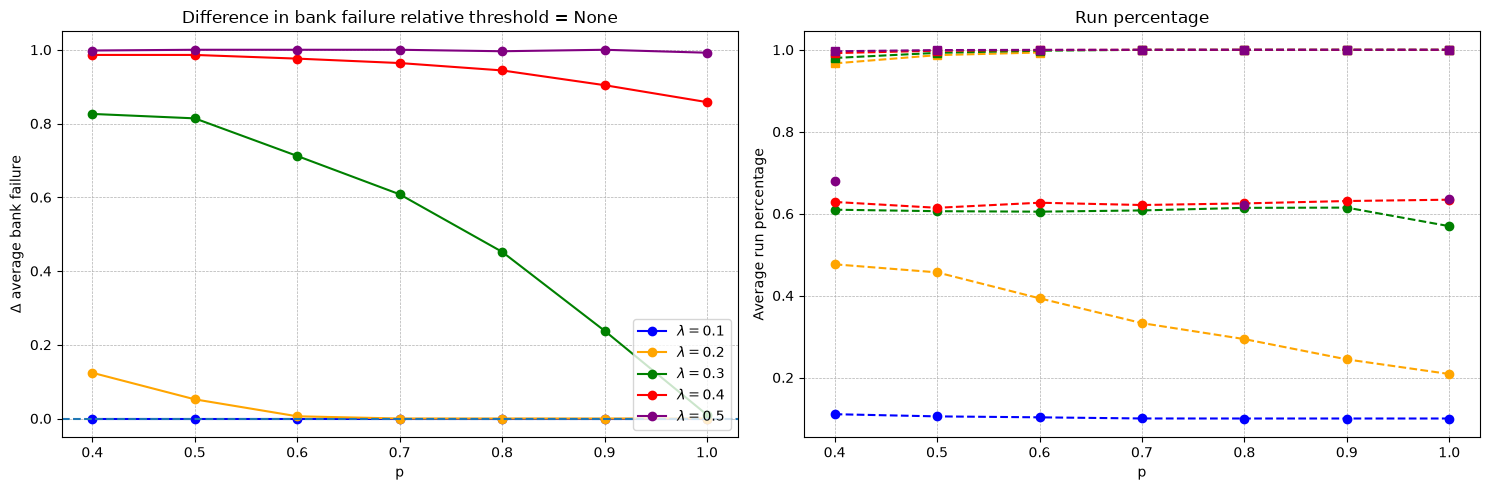

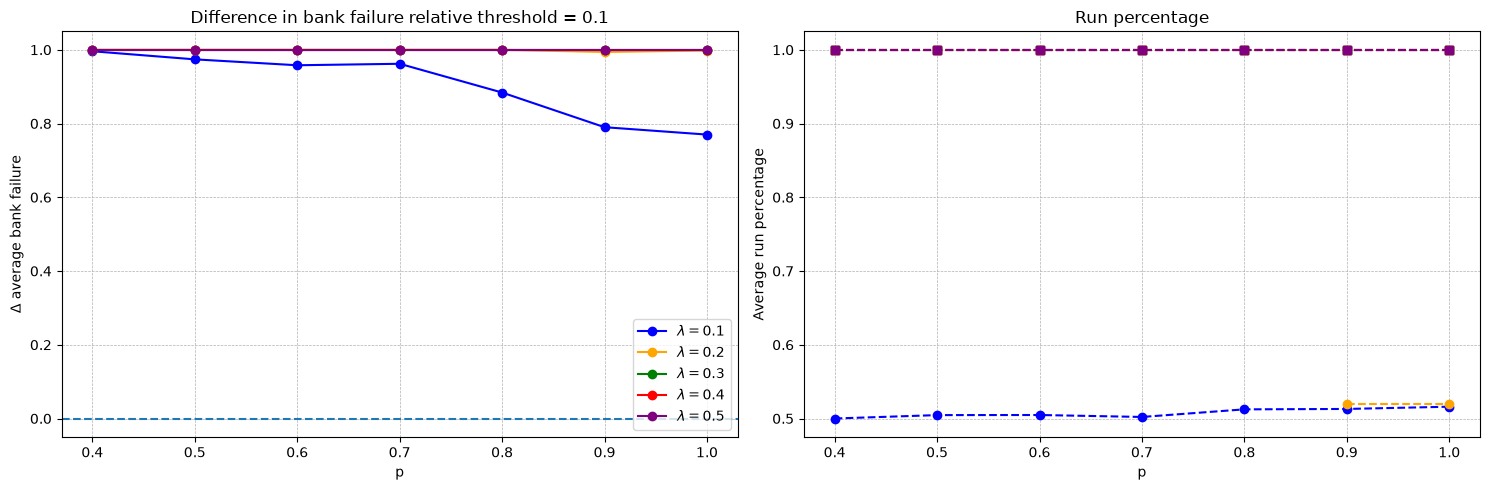

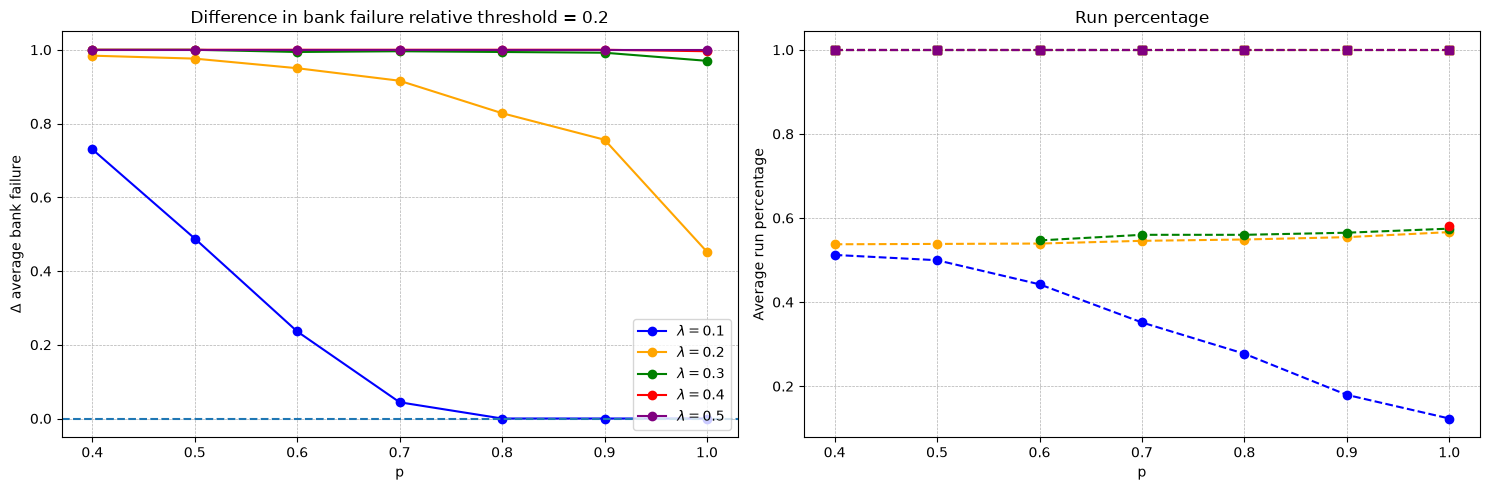

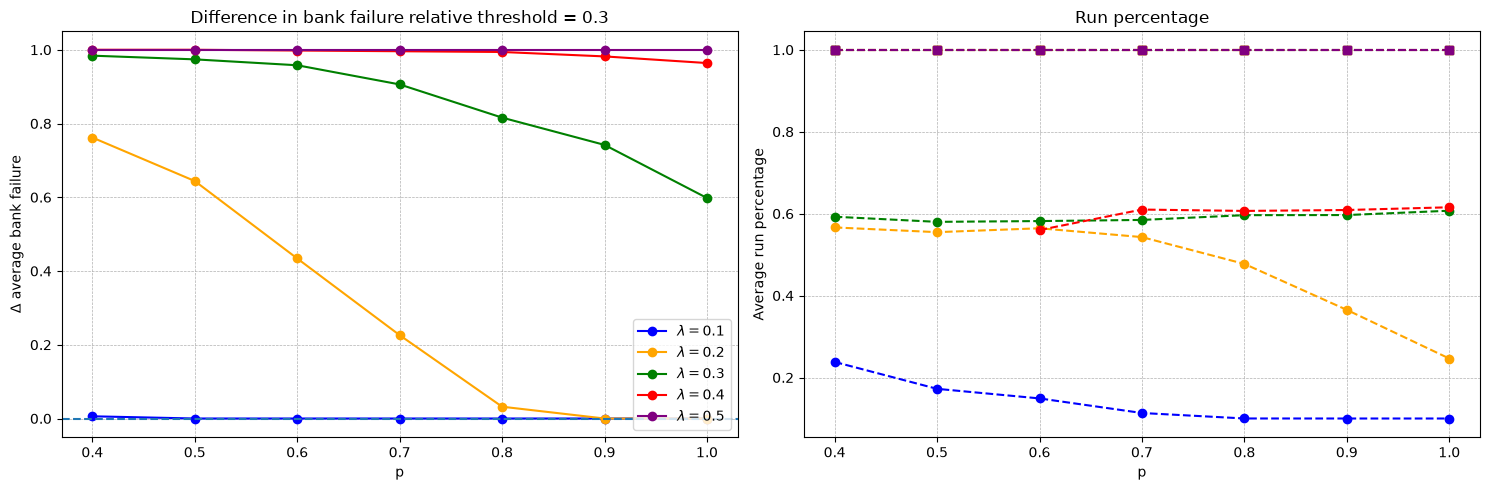

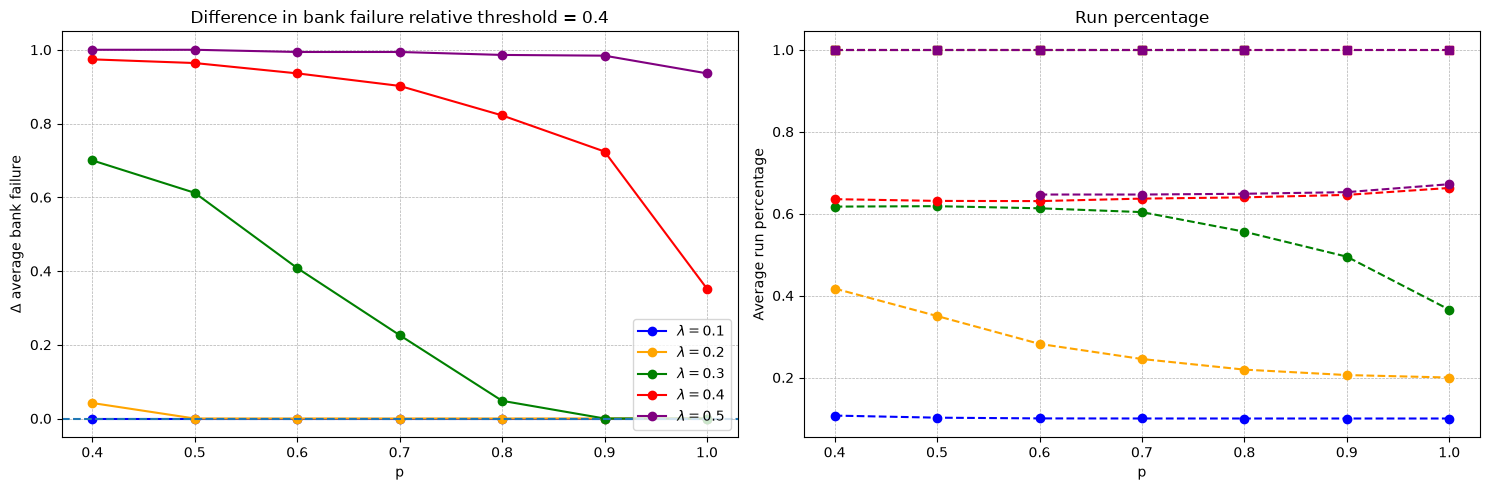

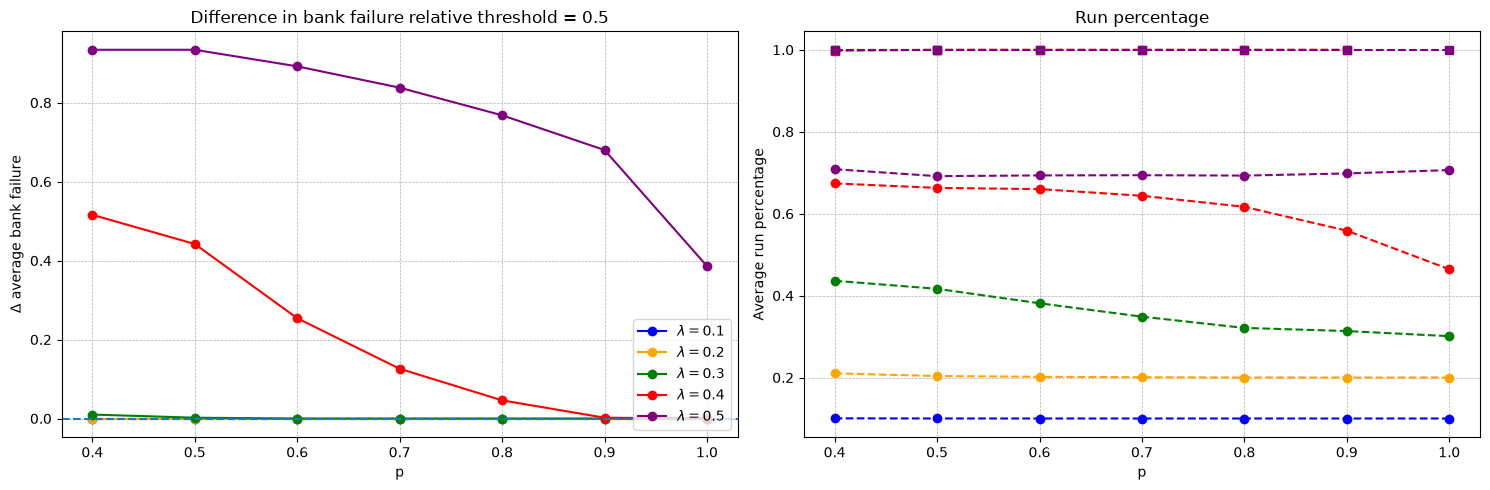

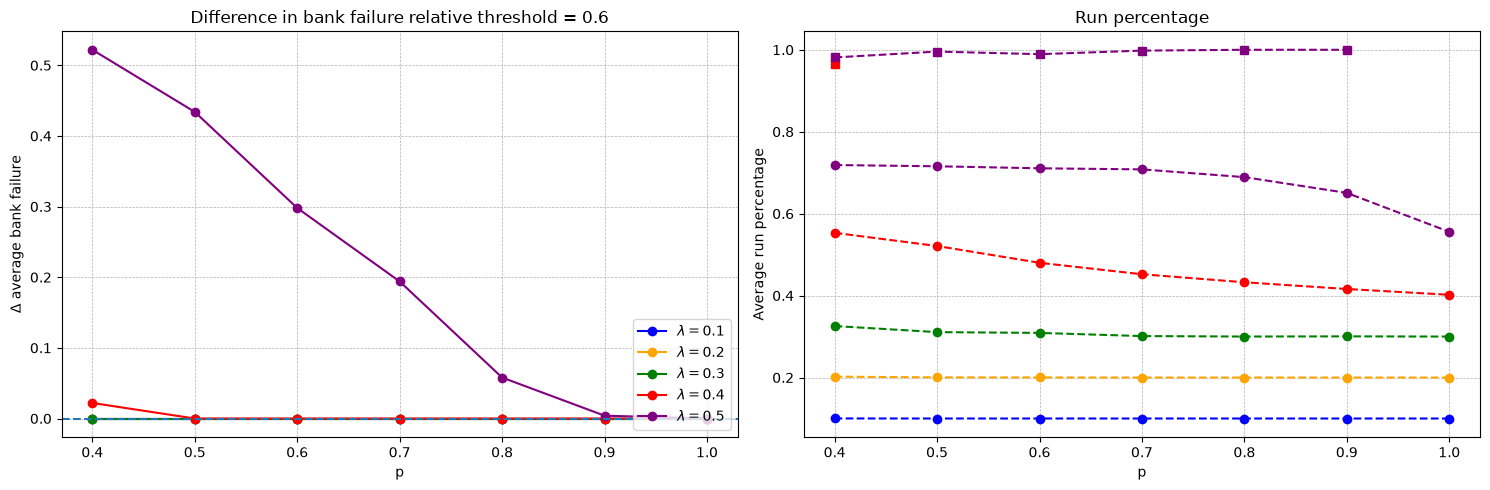

In [ ]:
for threshold in threshold_values:

    pivot = pivot_tables[threshold]
    pivot1 = pivot1_tables[threshold]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # =========================
    # LEFT GRAPH
    # =========================
    ax = axes[0]

    colors = ['blue', 'orange', 'green', 'red', 'purple']

    for color, lambda_value in zip(colors, Lambda_values):
        ax.plot(pivot.index, pivot[lambda_value], marker='o', label=fr'$\lambda={lambda_value}$', color=color)

    ax.set_title(rf'Difference in bank failure relative threshold = {threshold}')
    ax.set_xlabel('p')
    ax.set_ylabel(r'$\Delta$ average bank failure')
    ax.axhline(0, linestyle='--')
    ax.legend(loc='lower right')
    ax.grid(ls='dashed', lw=0.5)


    # =========================
    # RIGHT GRAPH
    # =========================
    ax = axes[1]
    for color, lambda_value in zip(colors, Lambda_values):
        for bank_failure, lam in pivot1.columns:
            if lam == lambda_value:
                if bank_failure is False:
                    ax.plot(pivot1.index, pivot1[(bank_failure, lam)], marker='o', ls = 'dashed', color = color)
                else:
                    ax.plot(pivot1.index, pivot1[(bank_failure, lam)], marker='s', ls = 'dashed', color = color)

    ax.set_title('Run percentage')
    ax.set_xlabel('p')
    ax.set_ylabel('Average run percentage')
    ax.grid(ls='dashed', lw=0.5)

    plt.tight_layout()
    plt.show()

## Number of Clusters = 3

In [ ]:
df_N503 = df[(df['N'] == 50) & (df['cluster'] == 3)].copy()

pivot_tables = {}
pivot1_tables = {}

for threshold in threshold_values:

    # Select the data for this threshold
    if threshold is None:
        temp = df_N503[df_N503['threshold'].isna()]
    else:
        temp = df_N503[df_N503['threshold'] == threshold]

    # LEFT: bank failure by lambda
    pivot = temp.pivot_table(index='p', columns='lambda', values='bank_failure', aggfunc='mean')

    pivot = pivot.reindex(columns=Lambda_values)

    pivot_tables[threshold] = pivot

    # RIGHT: run percentage by bank failure
    pivot1 = pd.pivot_table(temp, index='p', columns=['bank_failure', 'lambda'], values='run_percentage', aggfunc='mean')

    pivot1_tables[threshold] = pivot1

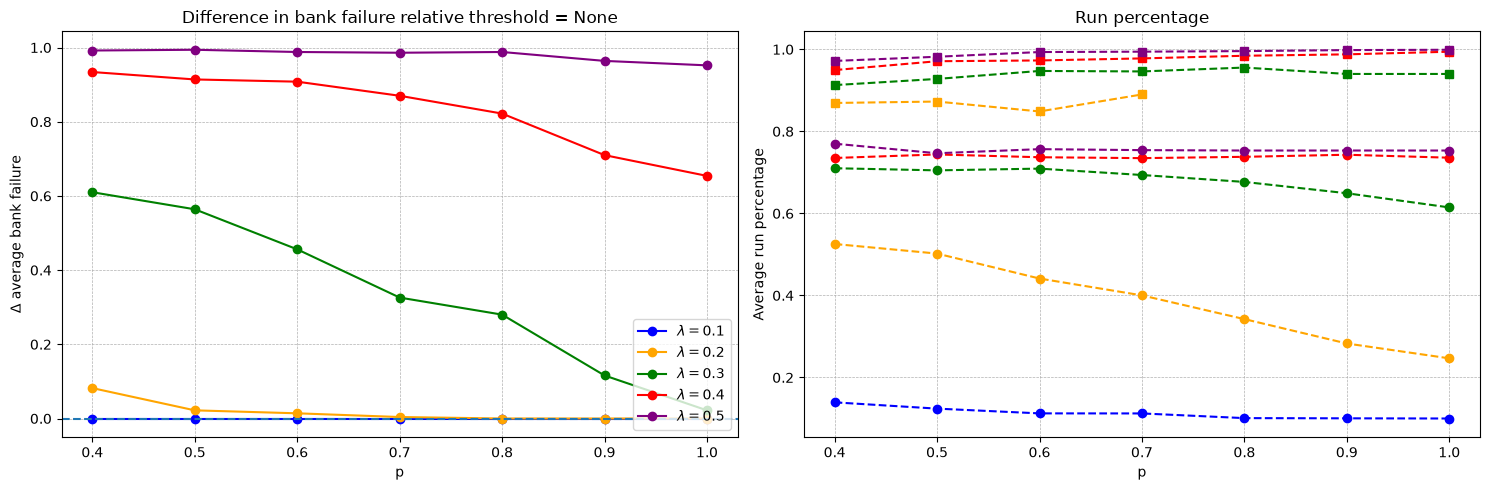

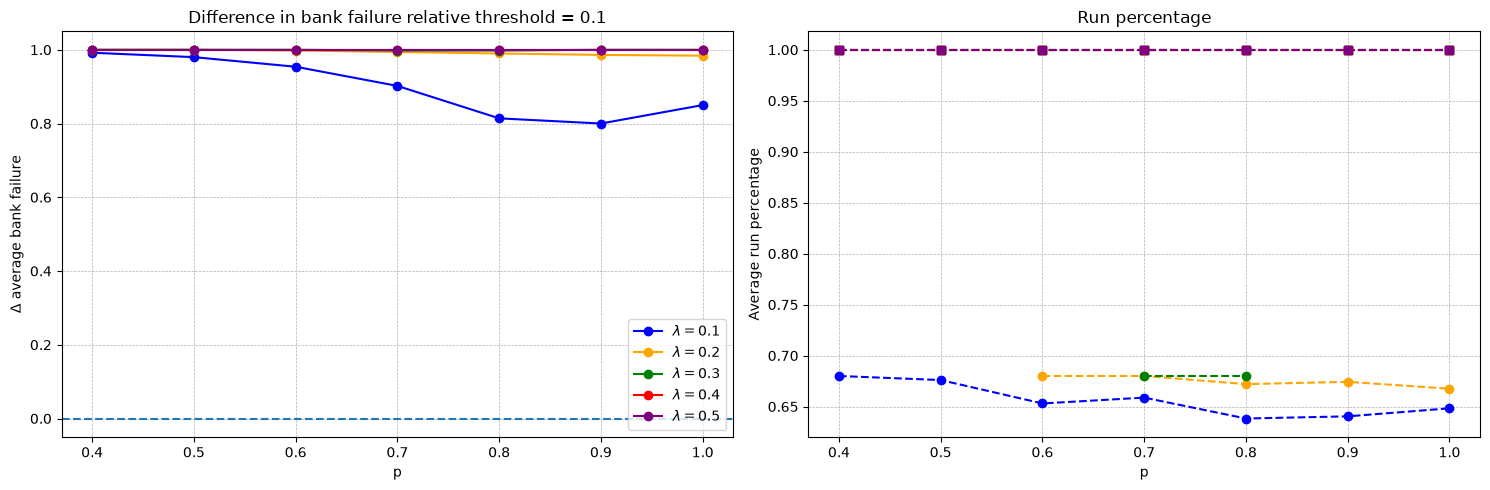

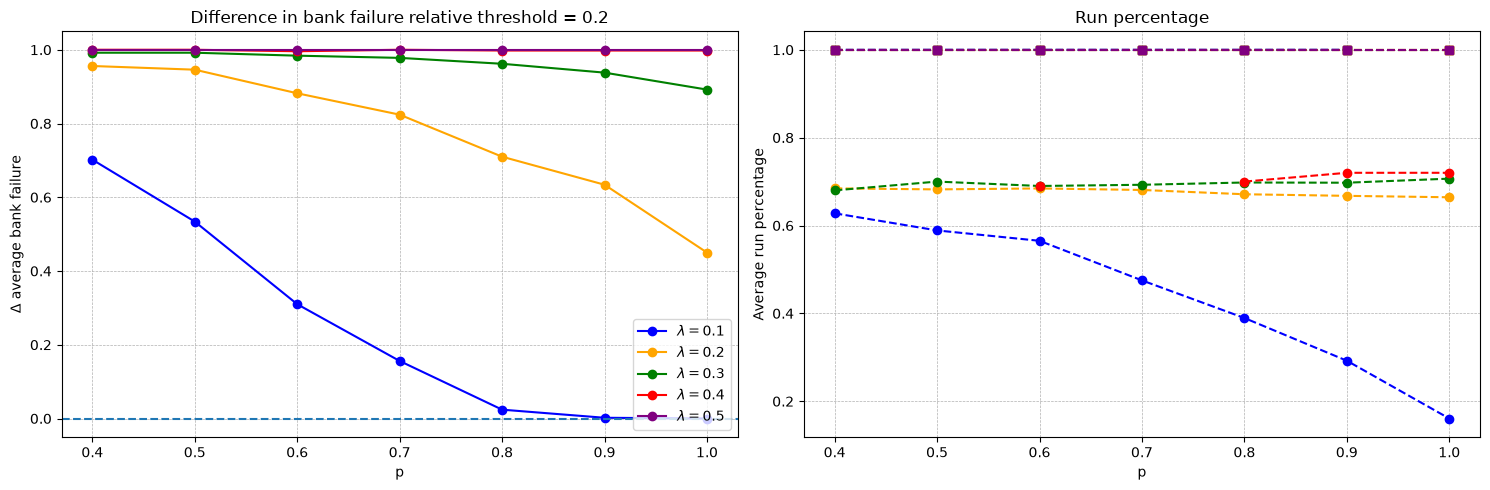

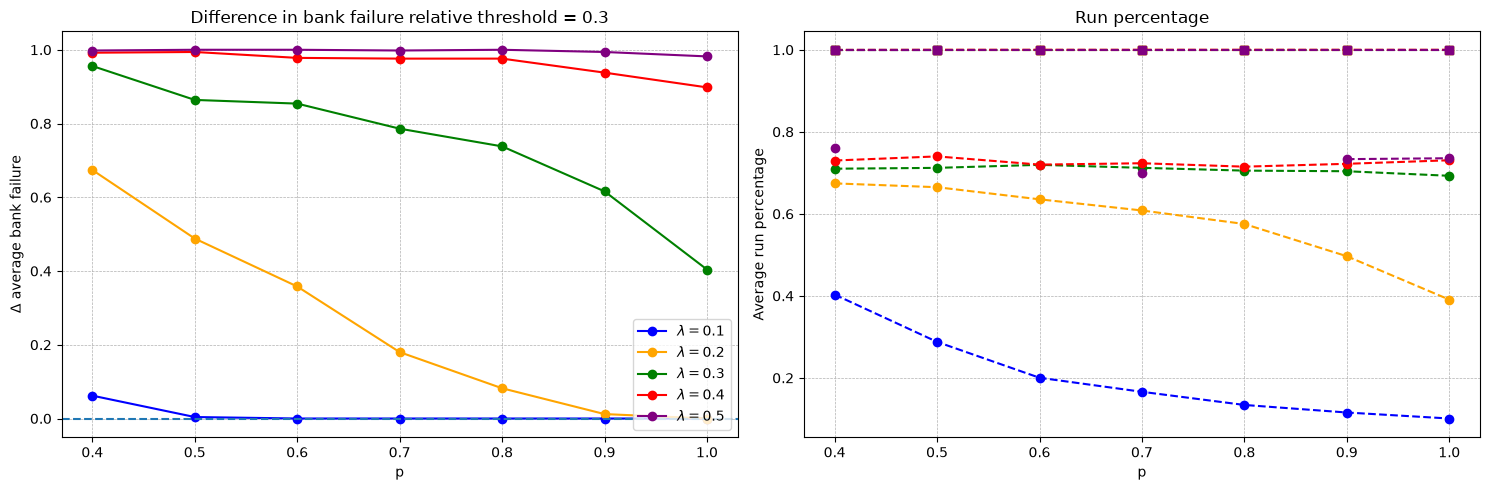

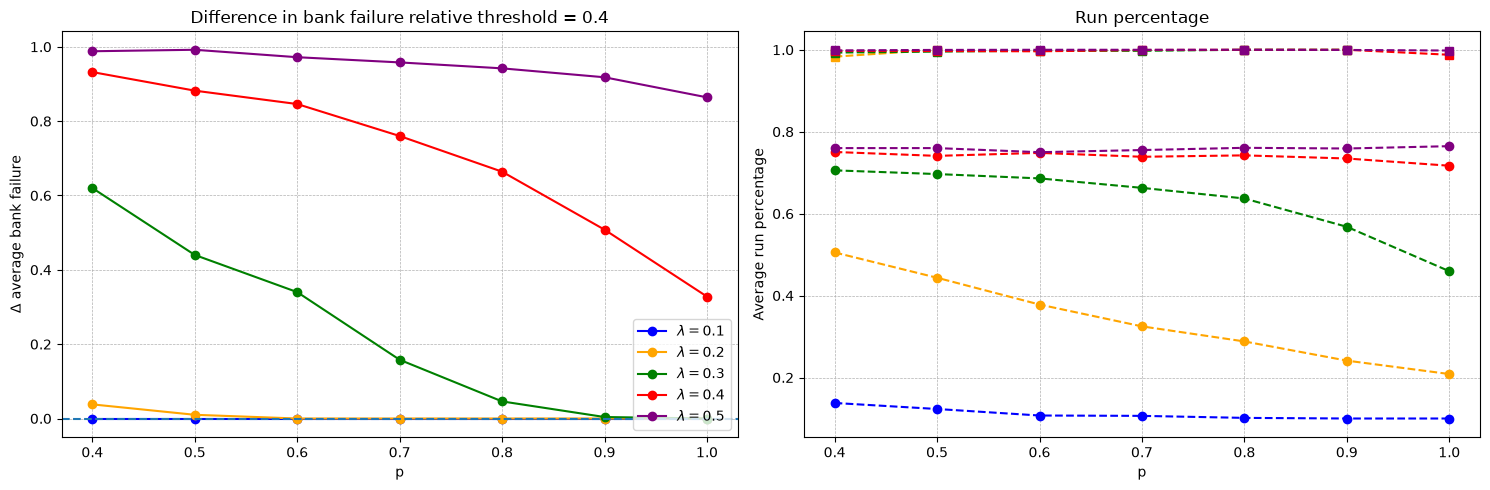

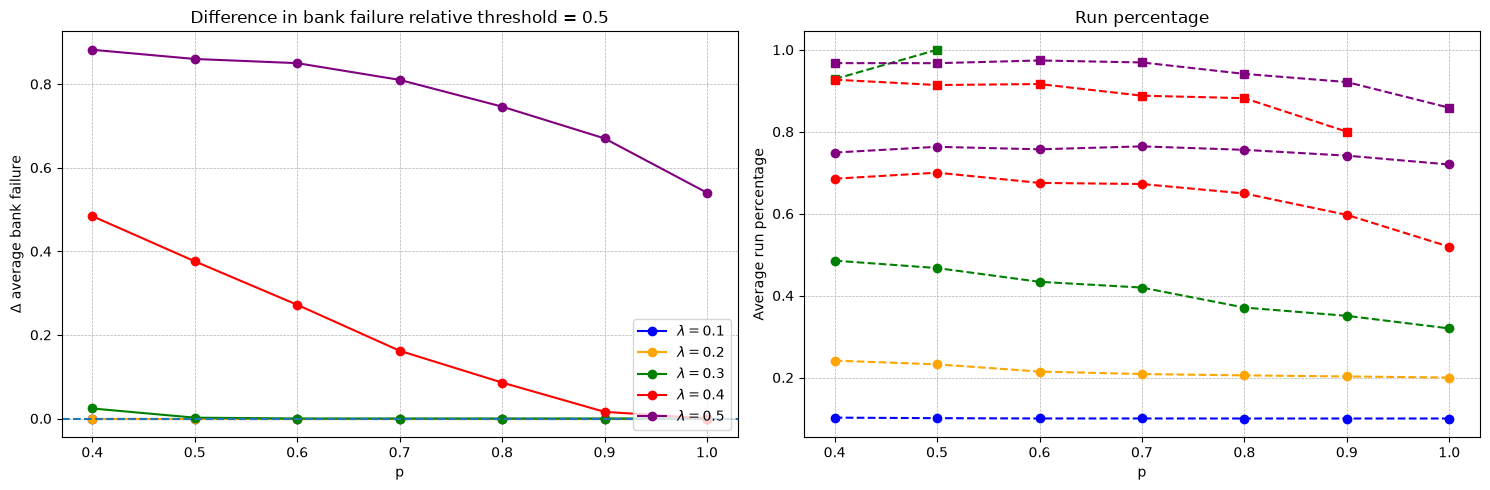

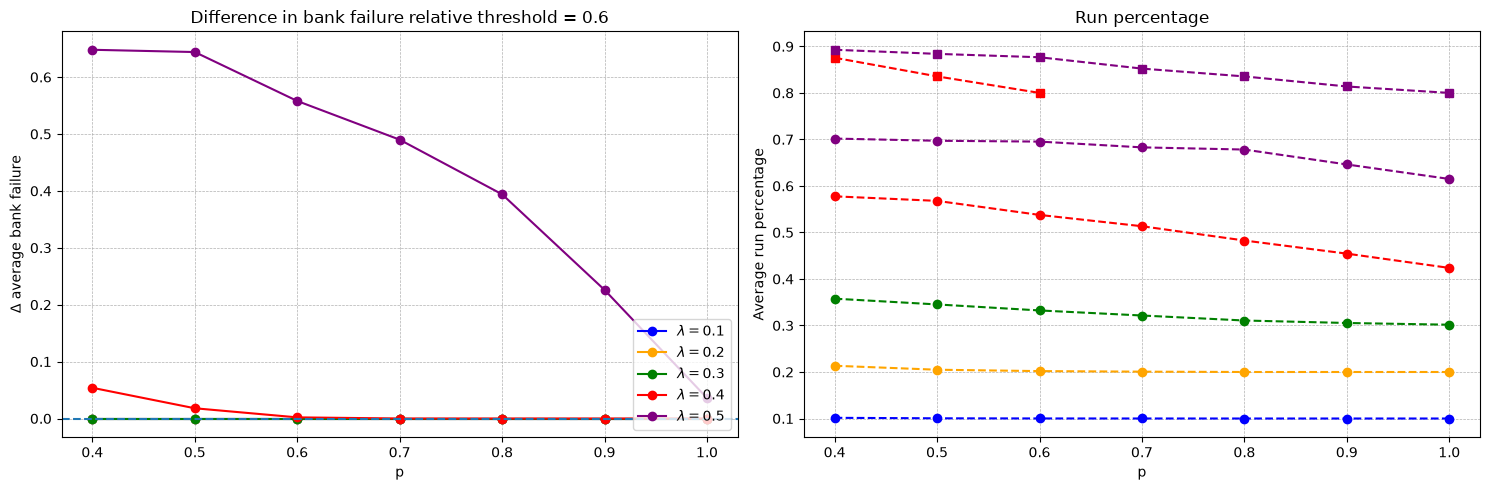

In [ ]:
for threshold in threshold_values:

    pivot = pivot_tables[threshold]
    pivot1 = pivot1_tables[threshold]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # =========================
    # LEFT GRAPH
    # =========================
    ax = axes[0]

    colors = ['blue', 'orange', 'green', 'red', 'purple']

    for color, lambda_value in zip(colors, Lambda_values):
        ax.plot(pivot.index, pivot[lambda_value], marker='o', label=fr'$\lambda={lambda_value}$', color=color)

    ax.set_title(rf'Difference in bank failure relative threshold = {threshold}')
    ax.set_xlabel('p')
    ax.set_ylabel(r'$\Delta$ average bank failure')
    ax.axhline(0, linestyle='--')
    ax.legend(loc='lower right')
    ax.grid(ls='dashed', lw=0.5)


    # =========================
    # RIGHT GRAPH
    # =========================
    ax = axes[1]
    for color, lambda_value in zip(colors, Lambda_values):
        for bank_failure, lam in pivot1.columns:
            if lam == lambda_value:
                if bank_failure is False:
                    ax.plot(pivot1.index, pivot1[(bank_failure, lam)], marker='o', ls = 'dashed', color = color)
                else:
                    ax.plot(pivot1.index, pivot1[(bank_failure, lam)], marker='s', ls = 'dashed', color = color)

    ax.set_title('Run percentage')
    ax.set_xlabel('p')
    ax.set_ylabel('Average run percentage')
    ax.grid(ls='dashed', lw=0.5)

    plt.tight_layout()
    plt.show()

## Number of Clusters = 4

In [ ]:
df_N504 = df[(df['N'] == 50) & (df['cluster'] == 4)].copy()

pivot_tables = {}
pivot1_tables = {}

for threshold in threshold_values:

    # Select the data for this threshold
    if threshold is None:
        temp = df_N504[df_N504['threshold'].isna()]
    else:
        temp = df_N504[df_N504['threshold'] == threshold]

    # LEFT: bank failure by lambda
    pivot = temp.pivot_table(index='p', columns='lambda', values='bank_failure', aggfunc='mean')

    pivot = pivot.reindex(columns=Lambda_values)

    pivot_tables[threshold] = pivot

    # RIGHT: run percentage by bank failure
    pivot1 = pd.pivot_table(temp, index='p', columns=['bank_failure', 'lambda'], values='run_percentage', aggfunc='mean')

    pivot1_tables[threshold] = pivot1

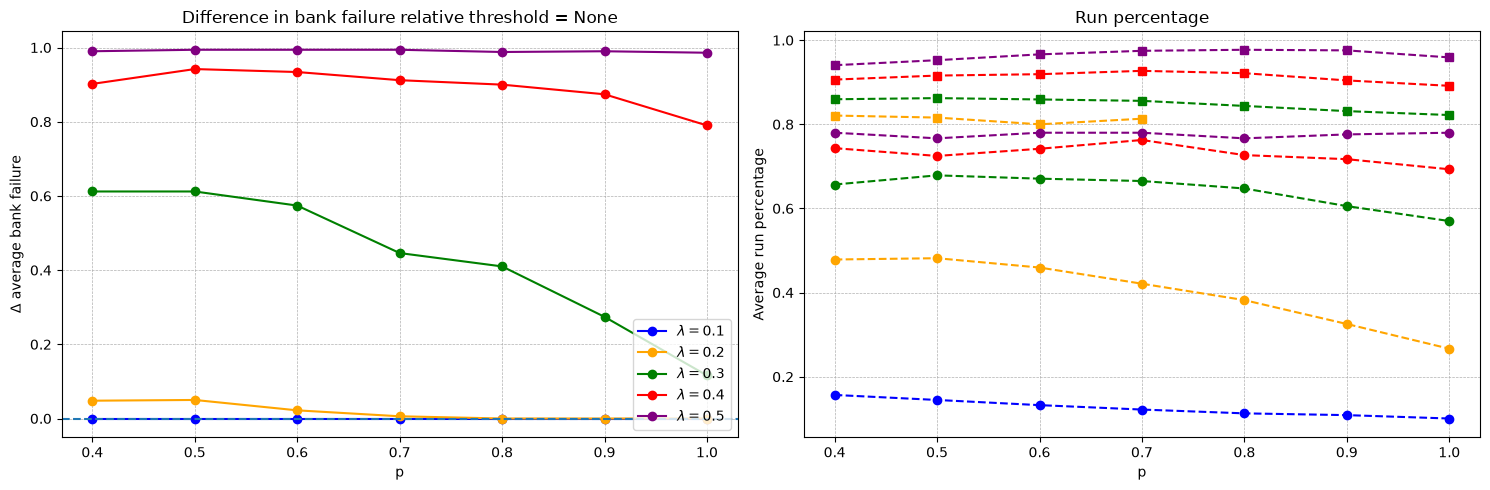

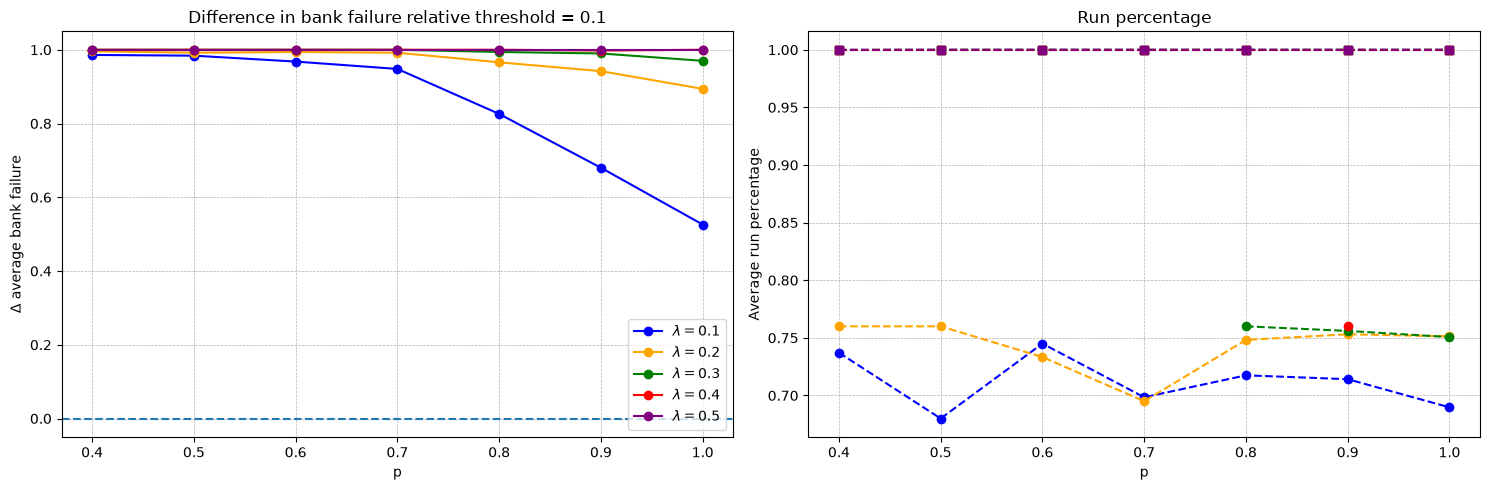

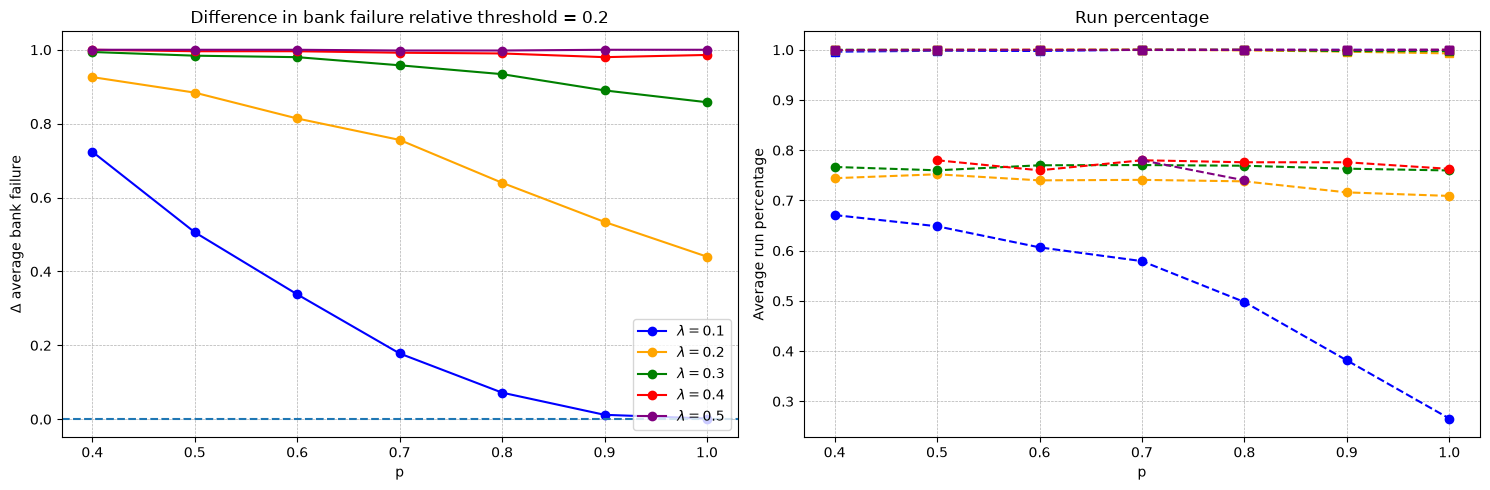

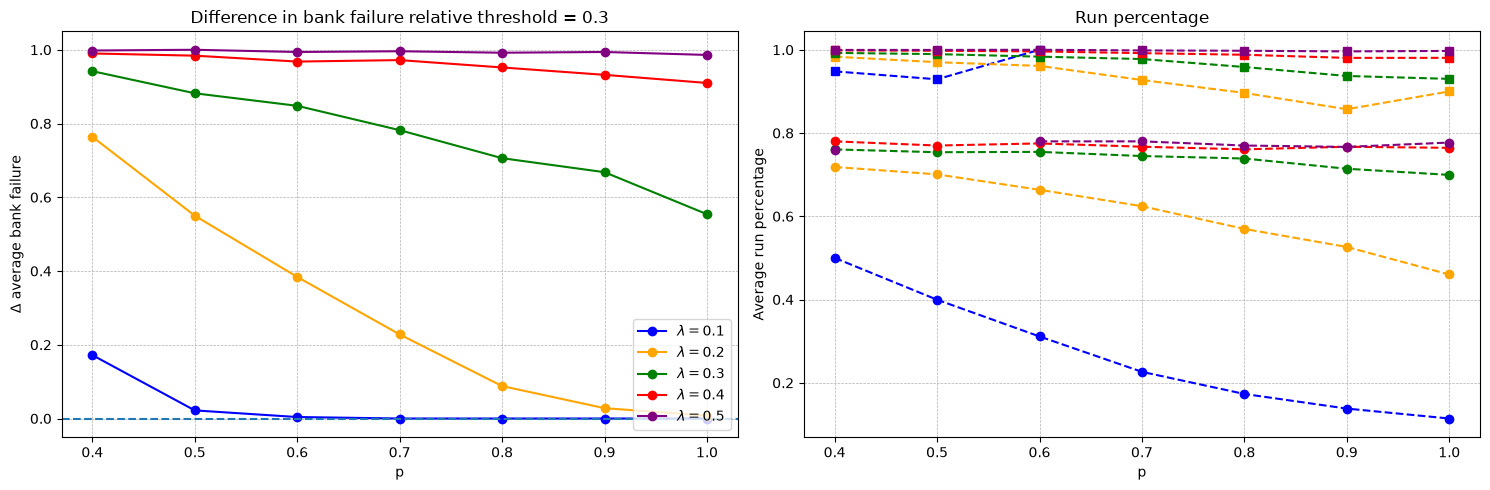

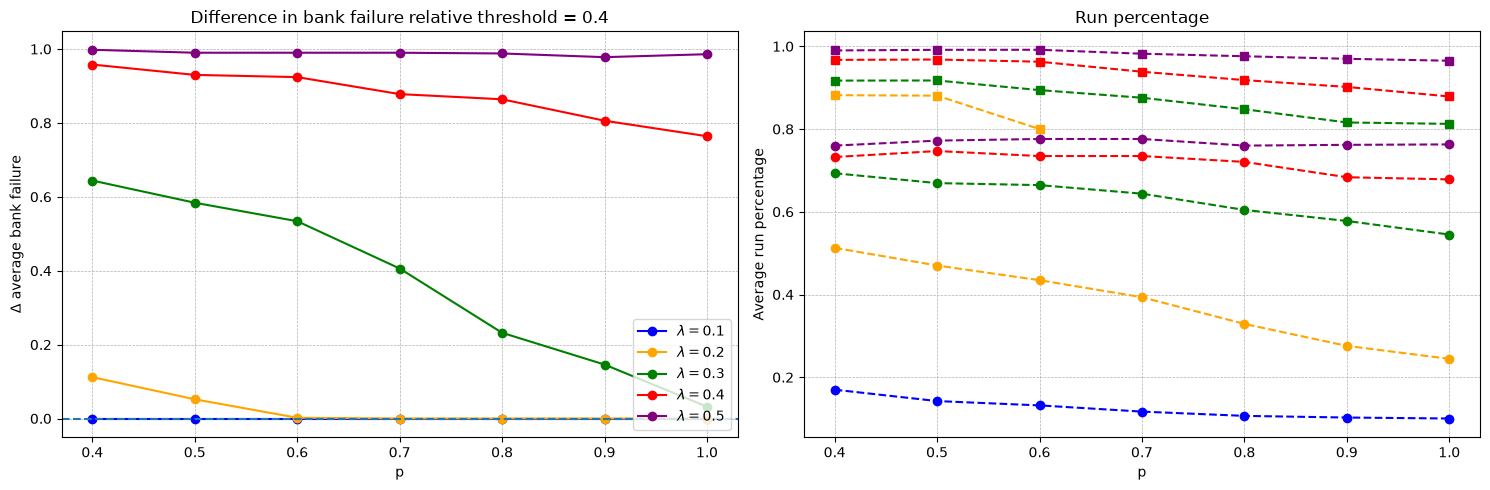

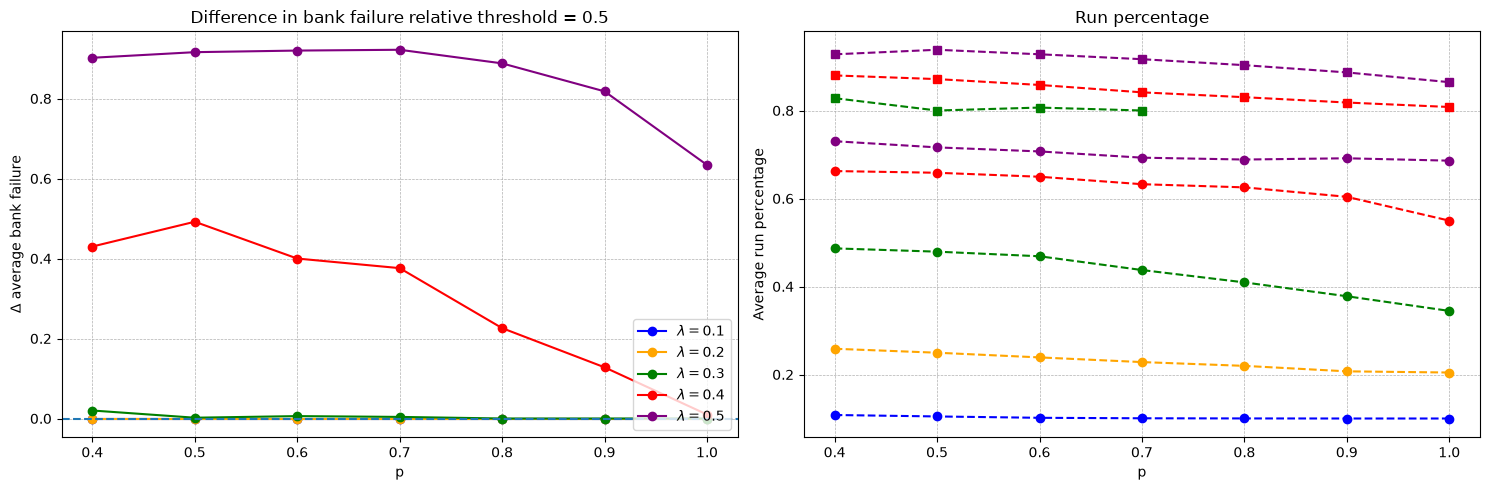

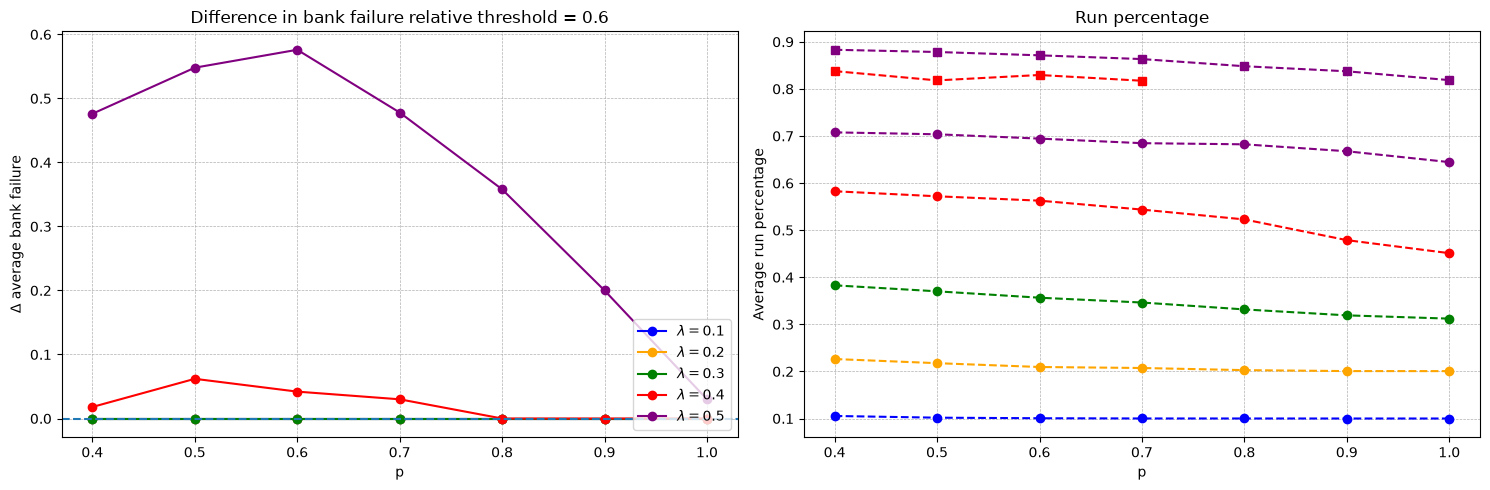

In [ ]:
for threshold in threshold_values:

    pivot = pivot_tables[threshold]
    pivot1 = pivot1_tables[threshold]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # =========================
    # LEFT GRAPH
    # =========================
    ax = axes[0]

    colors = ['blue', 'orange', 'green', 'red', 'purple']

    for color, lambda_value in zip(colors, Lambda_values):
        ax.plot(pivot.index, pivot[lambda_value], marker='o', label=fr'$\lambda={lambda_value}$', color=color)

    ax.set_title(rf'Difference in bank failure relative threshold = {threshold}')
    ax.set_xlabel('p')
    ax.set_ylabel(r'$\Delta$ average bank failure')
    ax.axhline(0, linestyle='--')
    ax.legend(loc='lower right')
    ax.grid(ls='dashed', lw=0.5)


    # =========================
    # RIGHT GRAPH
    # =========================
    ax = axes[1]
    for color, lambda_value in zip(colors, Lambda_values):
        for bank_failure, lam in pivot1.columns:
            if lam == lambda_value:
                if bank_failure is False:
                    ax.plot(pivot1.index, pivot1[(bank_failure, lam)], marker='o', ls = 'dashed', color = color)
                else:
                    ax.plot(pivot1.index, pivot1[(bank_failure, lam)], marker='s', ls = 'dashed', color = color)

    ax.set_title('Run percentage')
    ax.set_xlabel('p')
    ax.set_ylabel('Average run percentage')
    ax.grid(ls='dashed', lw=0.5)

    plt.tight_layout()
    plt.show()

# Simulation WS Network Results